# Comparing Greeks Across Credit Instruments

The same risk factor moves different credit products by very different amounts, and sometimes in opposite directions. This notebook prices seven common credit instruments (an auto loan, a mortgage, a floating-rate term loan, a revolver, a fixed-rate bond, a CDS, and a callable bond) inside one survival-discounting framework, $V_0=\sum_t D(0,t)[S(t)CF_t+q(t)R_t]$. It then bumps each risk factor and reprices to get a common set of Greeks, and graphs how the exposures differ.

## Risk factors

Each Greek in this notebook measures how much an instrument's price changes when one of these six factors moves, with the others held fixed. All prices, Greeks, and price changes in this notebook are in dollars per 100 dollars of notional.

| Factor | Definition | Bump used |
|---|---|---|
| **Rate** | The level of the risk-free interest rate $r$. A rate move shifts the whole curve in parallel, changing discount factors and every rate-linked cash flow: floating coupons and the mortgage refinancing rate. | +1bp |
| **Spread** | The credit spread $s$, the extra yield above the risk-free rate that investors demand for credit, liquidity, and funding risk. It is applied to discounting only, with cash flows held fixed, so it measures spread duration. | +1bp |
| **Hazard** | The hazard rate $h$, the annual default intensity: the probability of defaulting over the next instant given survival so far. It sets survival through $S(t)=e^{-ht}$. | +1bp per year |
| **Recovery** | The recovery rate $\rho$, the fraction of exposure at default the lender collects after default. Loss given default is $1-\rho$. | +1 percentage point |
| **CPR** | The conditional prepayment rate, the annualized fraction of the remaining balance borrowers repay early. It converts to a monthly rate through $SMM=1-(1-CPR)^{1/12}$. | +1 percentage point |
| **Gamma** | The second-order rate sensitivity, $P(r+25bp)+P(r-25bp)-2P(r)$ in dollars. Positive gamma (convexity) means large rate moves help the holder. Negative gamma, which embedded prepayment and call options create, means they hurt. | ±25bp |

## Market setup and instruments

Every instrument is sized to 100 dollars of notional, so dollar Greeks compare directly. Cash flows sit on a monthly grid. The risk-free curve is flat at $r=4.0\%$ (continuous), and $D(0,t)=e^{-(r+s)t}$, where $s$ is an extra discount spread that is zero at base and exists only to measure spread duration. Default follows a constant hazard (default intensity) $h$, so $S(t)=e^{-ht}$ and $q(t)=S(t-1)-S(t)$.

| Instrument | Terms | Hazard $h$ | Recovery $\rho$ |
|---|---|---|---|
| Auto loan | 7.5% APR, 60 months, 1% SMM prepayment, 50bp servicing | 3.6% (0.30%/month) | 45% |
| Mortgage | 30-year fixed at 6.5%; CPR $=6\%+20\max(6.5\%-r_{mkt}-0.25\%,0)$, $r_{mkt}=6\%+(r-4\%)$; 200bp OAS-style spread | 1% | 75% |
| Term loan (FRN) | 5-year bullet, coupon resets monthly to $r$ + 100bp | 2% | 55% |
| Revolver | 100 dollars commitment, 35 drawn, 250bp drawn spread over $r$, 45bp undrawn fee, CCF 70% | 2% | 55% |
| Fixed bond | 5-year, 5% semiannual coupon, recovery of face | 2% | 40% |
| CDS (buyer) | 5-year protection, 100bp contract spread paid quarterly | 2% | 40% |
| Callable bond | Fixed bond with a 5.5% coupon, callable at par on coupon dates from year 2 | 2% | 40% |

The callable bond is valued as the minimum over call dates of its risky PV, which is the issuer's optimal choice when the curve is deterministic. Because rates carry no volatility here, the option has no time value and the price curve kinks rather than bends smoothly. A rate tree with an OAS (option-adjusted spread) would smooth it.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd

base = dict(r=0.04, s=0.0, dh=0.0, drho=0.0, dcpr=0.0)


def curves(n, h, mkt):
    """Times, discount factors, survival, prior survival and marginal PD on a monthly grid."""
    t = np.arange(1, n + 1) / 12
    df = np.exp(-(mkt["r"] + mkt["s"]) * t)
    surv = np.exp(-(h + mkt["dh"]) * t)
    s_prev = np.r_[1, surv[:-1]]
    return t, df, surv, s_prev, s_prev - surv


def amort_loan(mkt, apr, n, h, rho, cpr, serv=0.0, oas=0.0):
    """Fixed-payment loan with default, recovery on opening balance, prepayment and servicing."""
    r = apr / 12
    k = np.arange(1, n + 1)
    pmt = 100 * r / (1 - (1 + r) ** -n)
    bal = np.maximum(100 * (1 + r) ** k - pmt * ((1 + r) ** k - 1) / r, 0)
    beg = np.r_[100, bal[:-1]]
    pd_m = 1 - np.exp(-(h + mkt["dh"]) / 12)
    smm = 1 - (1 - np.clip(cpr + mkt["dcpr"], 0, 0.99)) ** (1 / 12)
    df = np.exp(-(mkt["r"] + mkt["s"] + oas) * k / 12)
    s_prev = ((1 - pd_m) * (1 - smm)) ** (k - 1)
    perf = s_prev * (1 - pd_m)
    cf = perf * (pmt + smm * bal) + s_prev * pd_m * (rho + mkt["drho"]) * beg - s_prev * beg * serv / 12
    return (df * cf).sum()


def auto_loan(mkt):
    return amort_loan(mkt, 0.075, 60, -12 * np.log(1 - 0.003), 0.45, 1 - 0.99 ** 12, serv=0.005)


def mortgage(mkt):
    # refi incentive: contract rate minus market mortgage rate (6% at base, moves with r) minus 25bp cost
    incentive = max(0.065 - (0.06 + mkt["r"] - 0.04) - 0.0025, 0)
    return amort_loan(mkt, 0.065, 360, 0.01, 0.75, min(0.06 + 20 * incentive, 0.6), oas=0.02)


def term_loan(mkt, n=60, h=0.02, rho=0.55, spread=0.01):
    t, df, surv, s_prev, q = curves(n, h, mkt)
    cf = np.full(n, 100 * (np.exp(mkt["r"] / 12) - 1 + spread / 12))
    cf[-1] += 100
    return (df * (surv * cf + q * (rho + mkt["drho"]) * 100)).sum()


def revolver(mkt, n=60, h=0.02, rho=0.55, drawn=35, undrawn=65, ccf=0.7):
    t, df, surv, s_prev, q = curves(n, h, mkt)
    cf = np.full(n, drawn * (np.exp(mkt["r"] / 12) - 1 + 0.025 / 12) + undrawn * 0.0045 / 12)
    cf[-1] += drawn
    ead = drawn + ccf * undrawn
    # at default the lender funds the extra draw, then recovers a share of total EAD
    return (df * (surv * cf + q * ((rho + mkt["drho"]) * ead - ccf * undrawn))).sum()


def bond(mkt, n=60, h=0.02, rho=0.40, cpn=0.05, call_from=None):
    t, df, surv, s_prev, q = curves(n, h, mkt)
    rec = q * (rho + mkt["drho"]) * 100
    cf = np.zeros(n)
    cf[5::6] = 100 * cpn / 2
    pv_cf, pv_rec = np.cumsum(df * surv * cf), np.cumsum(df * rec)
    vals = [pv_cf[-1] + df[-1] * surv[-1] * 100 + pv_rec[-1]]
    if call_from:
        # issuer picks the call date that minimizes the bond's value (deterministic curve)
        vals += [pv_cf[m] + df[m] * surv[m] * 100 + pv_rec[m] for m in range(call_from - 1, n, 6)]
    return min(vals)


def callable_bond(mkt):
    return bond(mkt, cpn=0.055, call_from=24)


def cds(mkt, n=60, h=0.02, rho=0.40, spread=0.01):
    t, df, surv, s_prev, q = curves(n, h, mkt)
    rpv01 = (df * surv)[2::3].sum() * 0.25
    prot = (1 - rho - mkt["drho"]) * (df * q).sum()
    return 100 * (prot - spread * rpv01)


def cds_par(mkt=base, n=60, h=0.02, rho=0.40):
    t, df, surv, s_prev, q = curves(n, h, mkt)
    return (1 - rho) * (df * q).sum() / ((df * surv)[2::3].sum() * 0.25)


products = {"Auto loan": auto_loan, "Mortgage": mortgage, "Term loan (FRN)": term_loan,
            "Revolver": revolver, "Fixed bond": bond, "CDS (buyer)": cds, "Callable bond": callable_bond}

## Greeks

Each Greek is a central difference: the price change per 100 dollars for a +1 unit move in one factor, holding the others fixed. Signs are kept raw, so negative always means the holder loses value. This differs from the usual DV01 and CS01 conventions, which flip the sign. Gamma is reported in dollars rather than as percentage convexity because the CDS has a price near zero, which would make a percentage figure meaningless.

In [2]:
bumps = {"Rate +1bp": ("r", 1e-4), "Spread +1bp": ("s", 1e-4), "Hazard +1bp": ("dh", 1e-4),
         "Recovery +1pp": ("drho", 0.01), "CPR +1pp": ("dcpr", 0.01)}


def bump(fn, key, d, mkt=base):
    return fn({**mkt, key: mkt[key] + d})


def greeks(fn, mkt=base):
    """Central-difference price change per $100 for a +1 unit move in each factor, plus rate gamma."""
    g = {k: (bump(fn, key, d) - bump(fn, key, -d)) / 2 for k, (key, d) in bumps.items()}
    g["Gamma ±25bp"] = bump(fn, "r", 25e-4) + bump(fn, "r", -25e-4) - 2 * fn(mkt)
    return {"Price": fn(mkt), **g}


tbl = pd.DataFrame({k: greeks(f) for k, f in products.items()}).T
tbl.to_csv("greeks_table.csv")
tbl.style.format("{:+.4f}").format("{:.2f}", subset="Price")

,Price,Rate +1bp,Spread +1bp,Hazard +1bp,Recovery +1pp,CPR +1pp,Gamma ±25bp
Auto loan,101.96,-0.0202,-0.0202,-0.0113,+0.0713,-0.0315,+0.0037
Mortgage,101.13,-0.0382,-0.0499,-0.0131,+0.0491,-0.0587,-0.5177
Term loan (FRN),100.40,-0.0002,-0.0434,-0.0197,+0.0862,+0.0000,+0.0000
Revolver,36.90,-0.0005,-0.0156,-0.0161,+0.0694,+0.0000,+0.0001
Fixed bond,98.81,-0.0435,-0.0435,-0.0262,+0.0862,+0.0000,+0.0129
CDS (buyer),0.89,-0.0002,-0.0002,+0.0257,-0.0862,+0.0000,+0.0000
Callable bond,100.41,-0.0191,-0.0191,-0.0116,+0.0376,+0.0000,-0.0867


## Sanity checks

The auto loan is checked against an independent amortization-table valuation of the same loan at 30,000 principal with 6% monthly-compounded discounting, which gave a risky PV of 29,421.92.

In [3]:
bench_mkt = {**base, "r": 12 * np.log(1.005)}  # matches the benchmark valuation's 6% monthly-compounded discounting
assert abs(auto_loan(bench_mkt) * 300 - 29_421.92) < 0.01
assert abs(cds_par() - 0.02 * 0.6) < 5e-4 and abs(cds({**base}, spread=cds_par())) < 1e-10
assert abs(tbl.loc["Term loan (FRN)", "Rate +1bp"]) < 0.05 * abs(tbl.loc["Fixed bond", "Rate +1bp"])
assert tbl.loc["Mortgage", "Gamma ±25bp"] < 0 < tbl.loc["Fixed bond", "Gamma ±25bp"]
assert tbl.loc["Callable bond", "Gamma ±25bp"] < 0
assert all(bump(callable_bond, "r", x * 1e-4) <= bump(lambda m: bond(m, cpn=0.055), "r", x * 1e-4) for x in range(-200, 201, 5))
assert np.sign(tbl.loc["CDS (buyer)", ["Hazard +1bp", "Recovery +1pp"]]).tolist() == (-np.sign(tbl.loc["Fixed bond", ["Hazard +1bp", "Recovery +1pp"]])).tolist()
print(f"All checks passed. Auto loan benchmark (30,000 principal): {auto_loan(bench_mkt) * 300:,.2f}; CDS par spread: {cds_par():.4%}")

All checks passed. Auto loan benchmark (30,000 principal): 29,421.92; CDS par spread: 1.2070%


## Exposure map

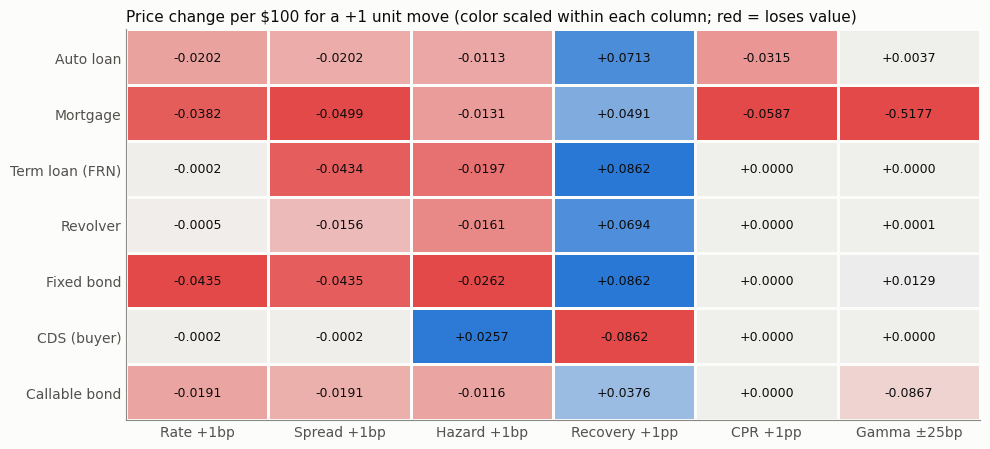

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

colors = dict(zip(products, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]))
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})

g = tbl.drop(columns="Price")
norm = g / g.abs().max().replace(0, 1)
cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.pcolormesh(norm.values, cmap=cmap, vmin=-1, vmax=1, edgecolors="#fcfcfb", linewidth=2)
for i in range(g.shape[0]):
    for j in range(g.shape[1]):
        ax.text(j + 0.5, i + 0.5, f"{g.iat[i, j]:+.4f}", ha="center", va="center", color="#0b0b0b", fontsize=9)
ax.set(xticks=np.arange(g.shape[1]) + 0.5, xticklabels=g.columns, yticks=np.arange(g.shape[0]) + 0.5,
       yticklabels=g.index)
ax.invert_yaxis()
ax.grid(False)
ax.tick_params(length=0)
ax.set_title("Price change per $100 for a +1 unit move (color scaled within each column; red = loses value)",
             loc="left", fontsize=11, color="#0b0b0b")
plt.tight_layout()
plt.show()

The heatmap shows that no single factor dominates across products. The fixed bond carries the largest rate exposure, losing 0.0435 per bp, while the floating term loan loses only 0.0002 because its coupon resets with the index. The floater still carries the same spread exposure as the fixed bond (−0.0434 versus −0.0435), which reflects the standard result that floating-rate structure removes interest-rate duration but not credit-spread duration. The CDS buyer is the mirror image of a bondholder on credit: it gains 0.0257 per bp of hazard and loses 0.0862 per point of recovery, the exact negative of the bond's recovery exposure.

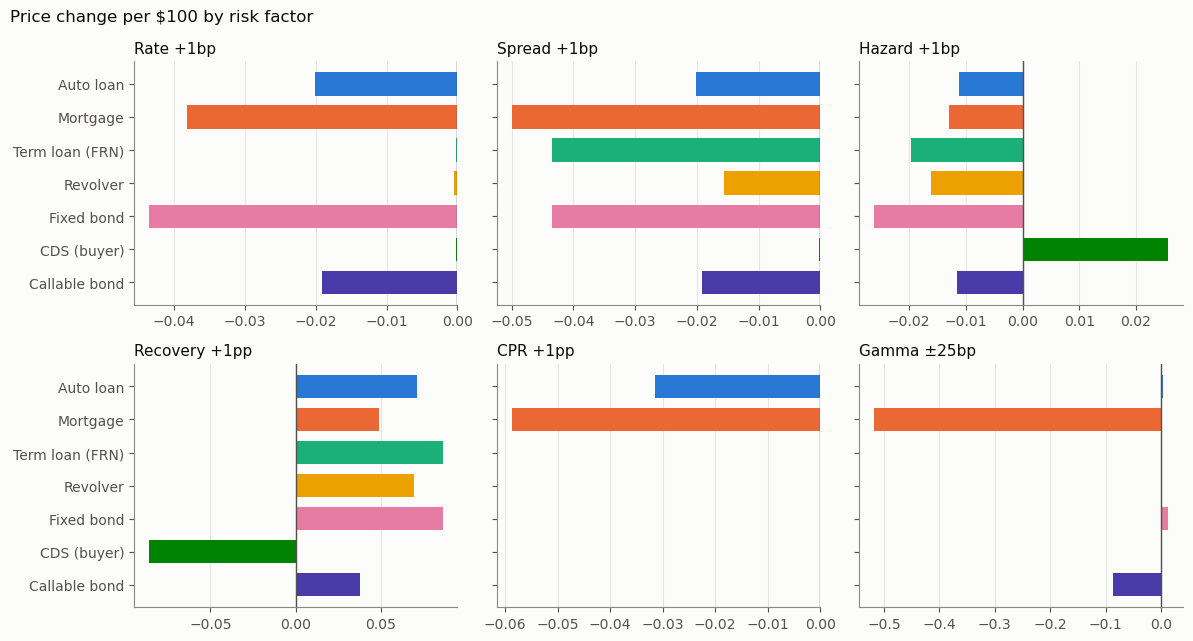

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharey=True)
for ax, col in zip(axes.flat, g.columns):
    ax.barh(g.index, g[col], color=[colors[p] for p in g.index], height=0.7)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_title(col, loc="left", fontsize=11, color="#0b0b0b")
    ax.grid(axis="y", visible=False)
axes[0, 0].invert_yaxis()
fig.suptitle("Price change per $100 by risk factor", x=0.01, ha="left", fontsize=12, color="#0b0b0b")
plt.tight_layout()
plt.show()

Reading one factor at a time shows where each product's risk sits. Prepayment risk lives only in the amortizing consumer products, and the mortgage loses about twice as much per CPR point as the auto loan (−0.0587 versus −0.0315), because it is priced at a premium and has a much longer life to give up. Gamma separates the products with embedded borrower or issuer options. The fixed bond has small positive gamma (+0.013), while the mortgage (−0.518) and the callable bond (−0.087) have negative gamma, so a large rate move in either direction costs their holders money.

## Rate scenarios

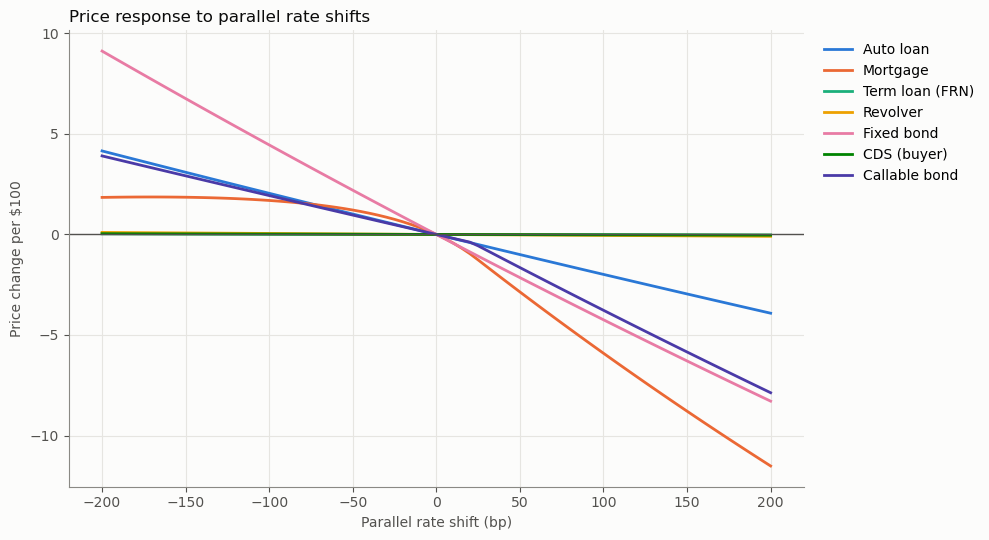

In [6]:
shifts = np.arange(-200, 201, 5)
fig, ax = plt.subplots(figsize=(10, 5.5))
for p, fn in products.items():
    ax.plot(shifts, [bump(fn, "r", x * 1e-4) - fn(base) for x in shifts], color=colors[p], lw=2, label=p)
ax.axhline(0, color="#52514e", lw=1)
ax.set(xlabel="Parallel rate shift (bp)", ylabel="Price change per $100")
ax.set_title("Price response to parallel rate shifts", loc="left", fontsize=12, color="#0b0b0b")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

The rate curves make negative convexity visible. The fixed bond gains 9.1 at −200bp and loses 8.3 at +200bp. The mortgage gains only 1.8 at −200bp, because falling rates accelerate refinancing and strip away its high-coupon cash flows, yet it loses 11.5 at +200bp as prepayment slows and the loan extends. The callable bond tracks a two-year bond below the kink near +25bp and a five-year bond above it, so its upside is capped in the same way. The floater, the revolver, and the CDS barely move.

## Credit scenarios

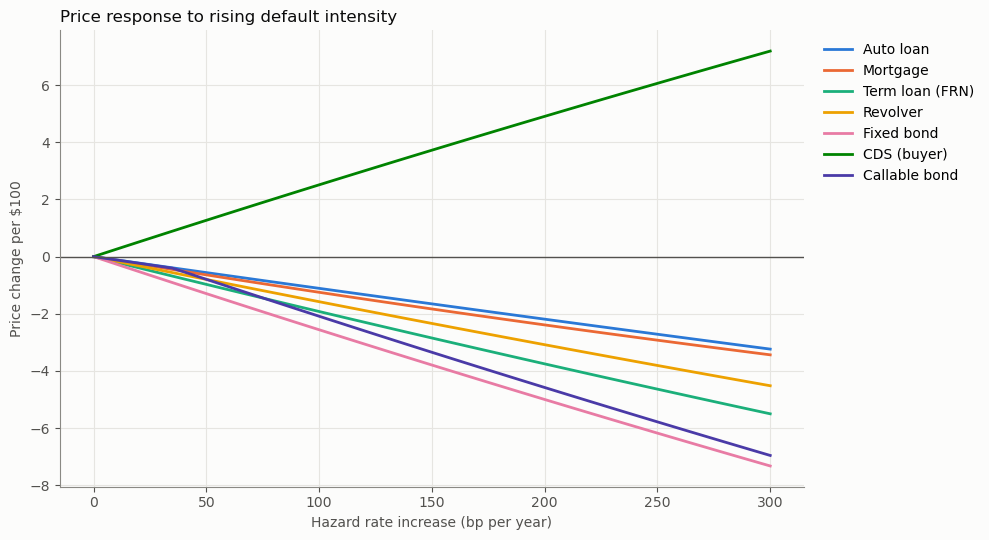

In [7]:
dhs = np.arange(0, 301, 5)
fig, ax = plt.subplots(figsize=(10, 5.5))
for p, fn in products.items():
    ax.plot(dhs, [bump(fn, "dh", x * 1e-4) - fn(base) for x in dhs], color=colors[p], lw=2, label=p)
ax.axhline(0, color="#52514e", lw=1)
ax.set(xlabel="Hazard rate increase (bp per year)", ylabel="Price change per $100")
ax.set_title("Price response to rising default intensity", loc="left", fontsize=12, color="#0b0b0b")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

Under rising default intensity, losses order by exposure at default and loss given default. At +300bp of hazard the fixed bond loses 7.32 and the callable bond 6.96, while the 75%-recovery mortgage loses only 3.44 and the amortizing auto loan 3.24, since its balance and therefore its exposure shrinks every month. The revolver loses 4.52 even though only 35 is drawn, because 70% of the undrawn line converts to exposure at default. The CDS buyer gains 7.19, which almost exactly offsets the bond, so it hedges credit risk but not rate risk.

## Conclusion

Risk-based valuation needs a full Greek vector, because each product concentrates its risk in a different factor. Fixed-rate bonds are rate and spread instruments, floating loans and revolvers are almost pure credit instruments, mortgages and callables are short options on rates with negative convexity, and the CDS isolates credit exposure with the opposite sign. The main sensitivity of this comparison is the prepayment function. Doubling the refinancing slope $\beta_1$ would make the mortgage's convexity more negative and its upside flatter, while the other products would not change.